# 07-03 - Stays and Trips

You turn GPS fixes into stays and trips with Lecture 07's stay rule, score the rule against a coded diary, and run your own trace of the hunt through the same chain.

First the toy's twelve fixes by hand, then visitor KP2's day at Knott's Berry Farm, from its gaps through the stay rule, its score, the trips and the trade between the two thresholds to what a stranger reads from it. Then your own trace. At the end you change the time threshold.

Before you run anything, choose *File*, then *Save As*, and give the copy a name with `-mywork` in it, so that the next pull never collides with your work.

In [1]:
import json

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import mob_tools as mob
from pathlib import Path

plt.rcParams["figure.dpi"] = 72

scene = json.load(open("data/scene.json"))
reference = json.load(open("data/ground_truth.json"))["p07"]
rules, anchors, lecture = scene["rules"], scene["anchors"], scene["lecture"]
print(f"Princeton's networks of {scene['snapshot']['graphs']} through osmnx {scene['snapshot']['osmnx']} in "
      f"{scene['crs']}; the specimen {reference['traces']['kp2']['fixes']:,} fixes; the stay rule "
      f"{rules['stay']['dist_m']:g} m and {rules['stay']['min_s'] / 60:g} minutes; the class's counts are "
      f"{'published' if reference['class_traces']['published'] else 'not published yet'}")

Princeton's networks of 2026-10-30 through osmnx 2.1.1 in EPSG:26918; the specimen 8,918 fixes; the stay rule 50 m and 10 minutes; the class's counts are not published yet


## The toy's twelve fixes

The cell runs the stay rule at 50 m and 10 minutes over the lecture's twelve fixes, prints the stays and the trip, and draws them on the toy.

a stay from 09:00 to 09:14, 14 min, 4 fixes
a stay from 09:24 to 09:40, 16 min, 4 fixes
 walked_m  straight_m  directness
   500.02      466.21        0.93
reference, directness 0.93


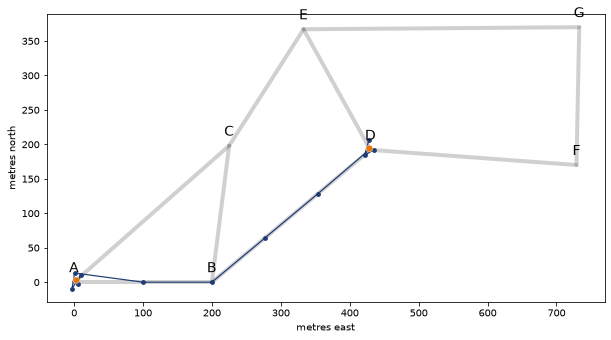

In [2]:
toy = pd.DataFrame(lecture["toy"]["fixes"])
toy_stays = mob.stays(toy, rules["stay"]["dist_m"], rules["stay"]["min_s"])
for s in toy_stays.itertuples():
    print(f"a stay from {mob.clock(s.start)} to {mob.clock(s.end)}, {s.duration_s / 60:.0f} min, {s.n} fixes")
print(mob.trips(toy, toy_stays)[["walked_m", "straight_m", "directness"]].round(2).to_string(index=False))
print(f"reference, directness {reference['traces']['toy']['trip']['directness']:.2f}")
fig, ax = plt.subplots(figsize=(10, 6), subplot_kw={"xlabel": "metres east", "ylabel": "metres north"})
mob.show_graph(mob.graph_from_edges(lecture["toy"]["edges"], lecture["toy"]["layout"]), ax, lw=4, alpha=0.3)
mob.show_traces(toy, ax, colour="#1f3b73", lw=1.2, stays_df=toy_stays)
ax.scatter(toy["x"], toy["y"], s=14, color="#1f3b73", zorder=2)
for name, (x, y) in lecture["toy"]["layout"].items():
    ax.annotate(name, (x, y), xytext=(0, 10), textcoords="offset points", ha="center", fontsize=14)

The rule anchors at a fix and extends the run while every later fix lies within 50 m of the anchor. When a fix breaks the circle, the run is kept as a stay if it lasted ten minutes, else the anchor moves one fix on. The four fixes at A span 14 minutes and the four at D span 16, so the rule keeps two stays. The four moving fixes between them make one trip, 500 m walked for 466 m of straight line, a directness of 0.93.

## The specimen

The cell reads visitor KP2's fixes with the park's outline and walkways, prints the day's span, and draws the track.

KP2 has 8,918 fixes from 12:05 to 18:09, 1 s apart at the median   reference 8,918, 12:05 to 18:09


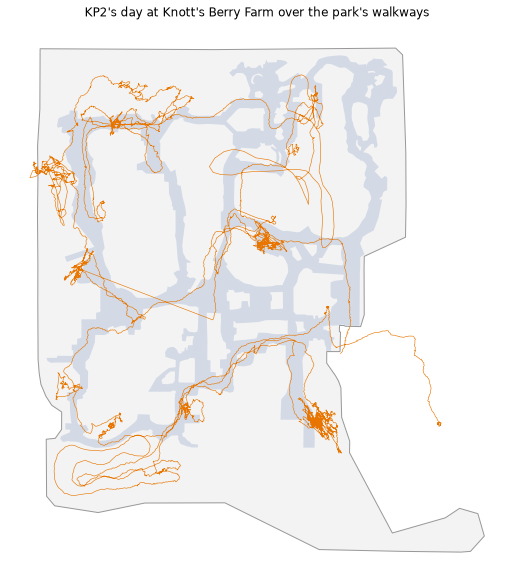

In [3]:
kp2, rk = mob.load_fixes("data/themepark_kp2.csv.gz"), reference["traces"]["kp2"]
park = gpd.read_file("data/themepark_kbf.gpkg", layer="ParkOutline")
paths = gpd.read_file("data/themepark_kbf.gpkg", layer="WalkingPaths")
print(f"KP2 has {len(kp2):,} fixes from {mob.clock(kp2['t_s'].min())} to {mob.clock(kp2['t_s'].max())}, "
      f"{kp2['t_s'].diff().median():.0f} s apart at the median"
      f"   reference {rk['fixes']:,}, {rk['first']} to {rk['last']}")
fig, ax = plt.subplots(figsize=(10, 10))
park.plot(ax=ax, facecolor="#f3f3f3", edgecolor="#999999")
paths.plot(ax=ax, color="#d3dae6")
mob.show_traces(kp2, ax, colour="#e77500", lw=0.6)
ax.set_title("KP2's day at Knott's Berry Farm over the park's walkways")
ax.set_axis_off()

A trajectory is a sequence of fixes, each a time, a position and an accuracy. KP2 carried a logger that writes one fix a second, so the day draws as a line along the walkways, with knots where the visitor queued, rode or ate. A phone in the background writes a fix every few minutes, and the same day would be a dotted line. The visitors appear as codes, with a clock and no date, and every track starts and ends at the gate.

## Where the fixes stop

The cell finds the gaps of over a minute between fixes, names the coded stop around the longest, and draws the speed against the clock, the gaps shaded.

17 gaps over a minute, the longest 39.2 minutes from 14:49 to 15:28 inside the coded Saloon   reference 17, 39.2, 14:49 Saloon

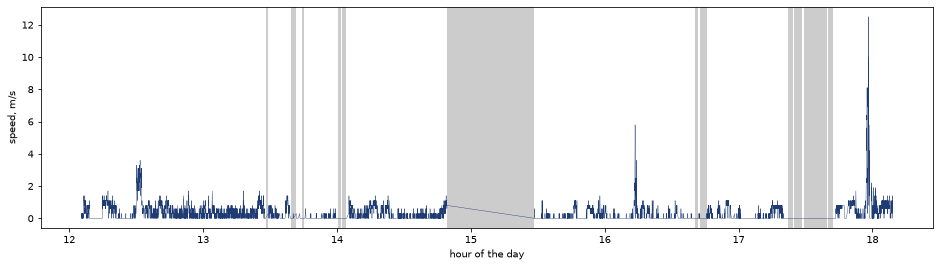

In [4]:
coded = mob.coded_stops(pd.read_csv("data/themepark_coded_stops.csv.gz"), "KP2")
t = kp2["t_s"].to_numpy()
gaps = pd.DataFrame({"start": t[:-1], "end": t[1:], "minutes": np.diff(t) / 60}).query("minutes > 1")
g = gaps.loc[gaps["minutes"].idxmax()]
host = ", ".join(coded[(coded["start"] <= g["start"]) & (coded["end"] >= g["end"])]["poi_name"])
print(f"{len(gaps)} gaps over a minute, the longest {np.round(g['minutes'], 1)} minutes from "
      f"{mob.clock(g['start'])} to {mob.clock(g['end'])} inside the coded {host}   reference "
      f"{rk['gaps_over_60_s']}, {rk['longest_gap_min']}, {rk['longest_gap_from']} {rk['longest_gap_inside']}")
fig, ax = plt.subplots(figsize=(16, 4), subplot_kw={"xlabel": "hour of the day", "ylabel": "speed, m/s"})
ax.plot(t / 3600, kp2["speed_mps"], lw=0.4, color="#1f3b73")
for a, b in zip(gaps["start"], gaps["end"]):
    ax.axvspan(a / 3600, b / 3600, color="#cccccc", lw=0)

The speed shows the day's rhythm, near zero at the stops, a walking pace between them and spikes on the rides. A receiver loses the sky under a roof, so the fixes stop where the visitor went indoors. The longest gap, 39.2 minutes from 14:49, falls inside the Saloon, the longest stop of the day. A gap is neither a stay nor a trip, and the stay rule sees only the fixes on either side of it.

## The stay rule, scored

The cell runs the rule over KP2's day, matches every stay to a coded stop it overlaps by a minute, and draws the stays as circles scaled by their duration.

11 stays, 8 of them matching one of the 15 coded stops with a clock time, precision 0.73, recall 0.53   reference 11, 8, 0.73, 0.53
missed Calico River Rapids 17.4 min, CRR Bathroom 2.8 min, CRR Bathroom 4.6 min, Wheeler Dealer 6.2 min, Lee's Last Stop Shop 3.0 min, Jaguar! 9.1 min, Sol Spin Line Stop 1.4 min


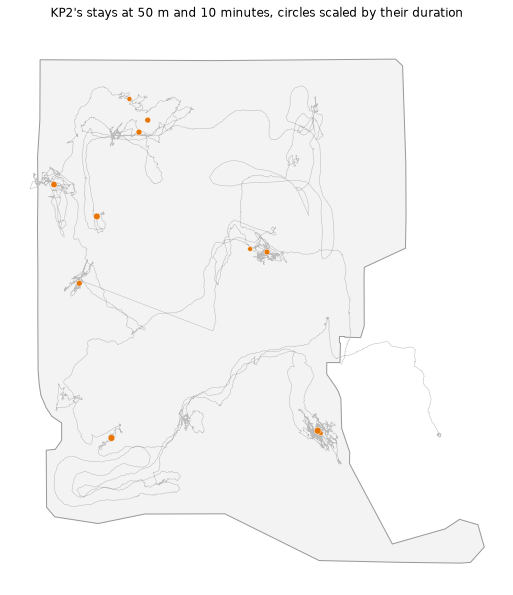

In [5]:
stays = mob.stays(kp2, rules["stay"]["dist_m"], rules["stay"]["min_s"])
score = mob.match_stays(stays, coded, min_overlap_s=rules["stay"]["overlap_s"])
print(f"{len(stays)} stays, {len(score['matched'])} of them matching one of the {len(coded)} coded stops "
      f"with a clock time, precision {score['precision']:.2f}, recall {score['recall']:.2f}   reference "
      f"{rk['n_detected']}, {rk['matched']}, {rk['precision']:.2f}, {rk['recall']:.2f}")
print("missed " + ", ".join(f"{coded.loc[j, 'poi_name']} {coded.loc[j, 'duration_min']:.1f} min"
                            for j in score["unmatched_coded"]))
fig, ax = plt.subplots(figsize=(10, 10))
park.plot(ax=ax, facecolor="#f3f3f3", edgecolor="#999999")
mob.show_traces(kp2, ax, colour="#bbbbbb", lw=0.5, stays_df=stays)
ax.set_title("KP2's stays at 50 m and 10 minutes, circles scaled by their duration")
ax.set_axis_off()

The study coded KP2's day by hand into stops, 15 of them with a clock time. Precision is the share of stays that match a coded stop, recall the share of coded stops that a stay found, the error matrix of Lecture 04 applied to stays. A stay and a stop match when their intervals overlap by a minute, one to one, the largest overlap first. The rule invents little and misses much, and the list above says which kind of stop slips through.

## The two timelines

The cell counts the coded stops shorter than the time threshold and draws the coded stops above the stays on the clock, pale where a bar found no partner.

7 coded stops under ten minutes, 6 of them missed; 3 stays match no coded stop   reference 7, 6, 3


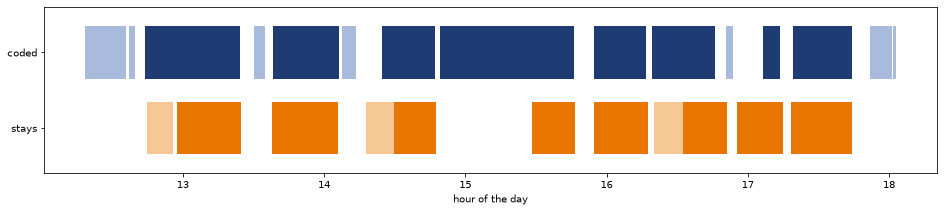

In [6]:
short = coded["duration_min"] < rules["stay"]["min_s"] / 60
missed = coded.index.isin(score["unmatched_coded"])
print(f"{short.sum()} coded stops under ten minutes, {(short & missed).sum()} of them missed; "
      f"{len(score['unmatched_detected'])} stays match no coded stop   reference {rk['coded_under_10_min']}, "
      f"{rk['coded_under_10_missed']}, {len(rk['unmatched_detected'])}")
fig, ax = plt.subplots(figsize=(16, 3))
ax.broken_barh(list(zip(coded["start"] / 3600, coded["duration_min"] / 60)), (0.65, 0.7),
               facecolors=np.where(missed, "#a9bbdc", "#1f3b73"))
ax.broken_barh(list(zip(stays["start"] / 3600, stays["duration_s"] / 3600)), (-0.35, 0.7),
               facecolors=np.where(stays.index.isin(score["unmatched_detected"]), "#f6c896", "#e77500"))
ax.set(yticks=[0, 1], yticklabels=["stays", "coded"], xlabel="hour of the day", ylim=(-0.6, 1.6))
plt.show()

The misses are the rule's, not the data's. Seven coded stops lasted under ten minutes, two bathroom stops, a shop, two short rides and two unlabelled stops, and six were missed; the seventh, Sky Cabin, was found because a longer stay overlaps it. Calico River Rapids lasted 17 minutes and was missed too, since no ten minutes of its fixes stayed within 50 m of an anchor. Each pale stay sits under a stop another stay matched, a queue that snaked over 50 m and was cut in two.

## Trips and directness

The cell lists the trips between consecutive stays with their clock times, the metres walked along the fixes, the straight line between the two stays and the directness.

In [7]:
trips = mob.trips(kp2, stays)
moves = trips[trips["straight_m"] >= rules["stay"]["dist_m"]]
table = trips.assign(start=trips["start"].map(mob.clock), end=trips["end"].map(mob.clock))
print(table[["start", "end", "walked_m", "straight_m", "directness"]].round(2).to_string())
print(f"{len(trips)} trips, the {len(moves)} between stays at least 50 m apart at a mean directness of "
      f"{moves['directness'].mean():.2f}   reference {rk['trips']}, {rk['n_between_places']}, "
      f"{rk['directness_mean_between_places']:.2f}")
print(f"the study's mean directness on the walkways {rk['paper_directness']:.2f}")

   start    end  walked_m  straight_m  directness
0  12:55  12:57     74.86        4.18        0.06
1  13:24  13:37    506.82      219.16        0.43
2  14:05  14:17    599.81      248.94        0.42
3  14:29  14:29      1.08       18.22       16.92
4  14:47  15:28    297.90      202.06        0.68
5  15:46  15:54    280.85      108.31        0.39
6  16:17  16:20    120.34      121.18        1.01
7  16:32  16:32      1.38       29.69       21.45
8  16:51  16:55    136.34       15.83        0.12
9  17:15  17:18    217.16      100.01        0.46
10 trips, the 6 between stays at least 50 m apart at a mean directness of 0.56   reference 10, 6, 0.56
the study's mean directness on the walkways 0.70


Directness here is the straight line between two stays over the metres walked between them, one for a bee line. Two trips last a second, between the halves of a split queue, where the straight line between the halves' centres is longer than the metre walked, so their directness runs far above one. Leaving out the trips between stays under 50 m apart, the mean is 0.56. The study's 0.70 divides the shortest path on the walkways by the walk, and no path is shorter than the straight line.

## One leg, drawn

The cell cuts the fixes between the end of Wheeler Dealer and the start of Silver Bullet, prints the study's measure of that leg, and draws it on the walkways.

Wheeler Dealer 14:13 to Silver Bullet 14:24, 647 m walked for a shortest path of 313 m, directness 0.48   reference 0.48


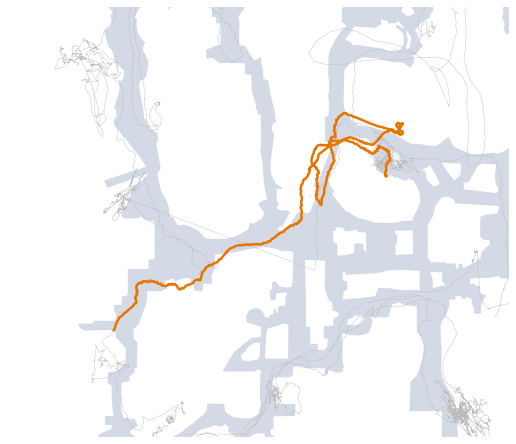

In [8]:
leg, rl = coded[coded["poi_name"] == "Silver Bullet"].iloc[0], reference["traces"]["leg"]
before = coded.loc[leg.name - 1]
on_leg = kp2[kp2["t_s"].between(before["end"], leg["start"])]
print(f"{before['poi_name']} {mob.clock(before['end'])} to {leg['poi_name']} {mob.clock(leg['start'])}, "
      f"{leg['walked_dist_m']:.0f} m walked for a shortest path of {leg['shortest_path_m']:.0f} m, "
      f"directness {leg['path_directness']:.2f}   reference {rl['directness']:.2f}")
fig, ax = plt.subplots(figsize=(9, 9))
paths.plot(ax=ax, color="#d3dae6")
mob.show_traces(kp2, ax, colour="#bbbbbb", lw=0.4)
ax.plot(on_leg["x"], on_leg["y"], color="#e77500", lw=2.5)
ax.set(xlim=on_leg["x"].agg(["min", "max"]) + [-80, 80], ylim=on_leg["y"].agg(["min", "max"]) + [-80, 80])
ax.set_axis_off()

The visitor walked 647 m where the walkways offered 313 m, a directness of 0.48, and the surplus is a detour past other attractions on the way. A directness far below one is a story, a detour, a queue or a stroll, not an error. To compare a walk with a network, map matching first lays the fixes on it, in its simplest form by snapping each fix to the nearest edge, in its standard form by a hidden Markov model that chooses the path best explaining the whole sequence.

## Fifteen visitors on the paths

The cell reads the fixes of all fifteen analysed Knott's visitors, measures how many lie within 10 m of a walkway, and draws those that do not.

15 visitors and 94,389 fixes, 76% of them within 10 m of a walkway   reference 15, 94,389, 76%


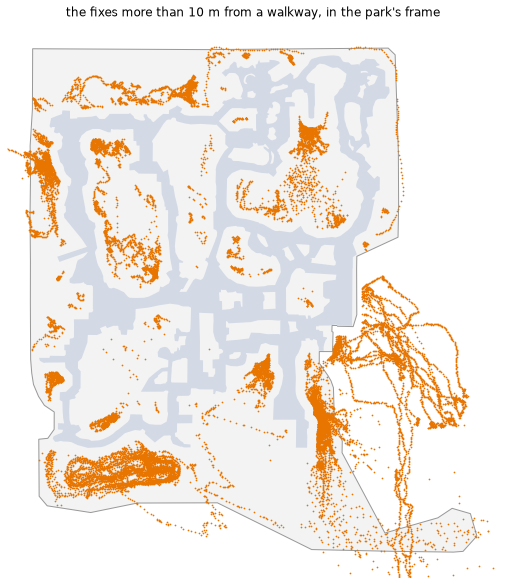

In [9]:
fixes = pd.read_csv("data/themepark_kbf_fixes.csv.gz")
near = gpd.GeoSeries(gpd.points_from_xy(fixes["x"], fixes["y"])).distance(paths.union_all()) <= 10.0
ro = reference["traces"]["on_paths"]
print(f"{fixes['participant_id'].nunique()} visitors and {len(fixes):,} fixes, {near.mean():.0%} of them "
      f"within 10 m of a walkway   reference {ro['visitors']}, {ro['fixes']:,}, {ro['share']:.0%}")
fig, ax = plt.subplots(figsize=(10, 10))
park.plot(ax=ax, facecolor="#f3f3f3", edgecolor="#999999")
paths.plot(ax=ax, color="#d3dae6")
ax.autoscale(False)
ax.scatter(fixes["x"][~near], fixes["y"][~near], s=0.5, color="#e77500")
ax.set_title("the fixes more than 10 m from a walkway, in the park's frame")
ax.set_axis_off()

Three quarters of the fixes lie within 10 m of a walkway. The rest were recorded in queues, inside rides and shops, at tables, at the shows and beyond the gate, where the walkway layer has no line, and by receivers that drift while their wearers stand still. A path network is a model of where people walk, and a quarter of a day at the park is spent off it. Your own trace meets Princeton's walk network the same way at the end of this notebook.

## The two thresholds, traded

The cell runs the rule at every pair of the lecture's thresholds on KP2's day and draws precision and recall above the lecture's surfaces for the fifteen visitors pooled.

pooled at 50 m and 10 min 0.75, 0.54   reference 0.75, 0.54


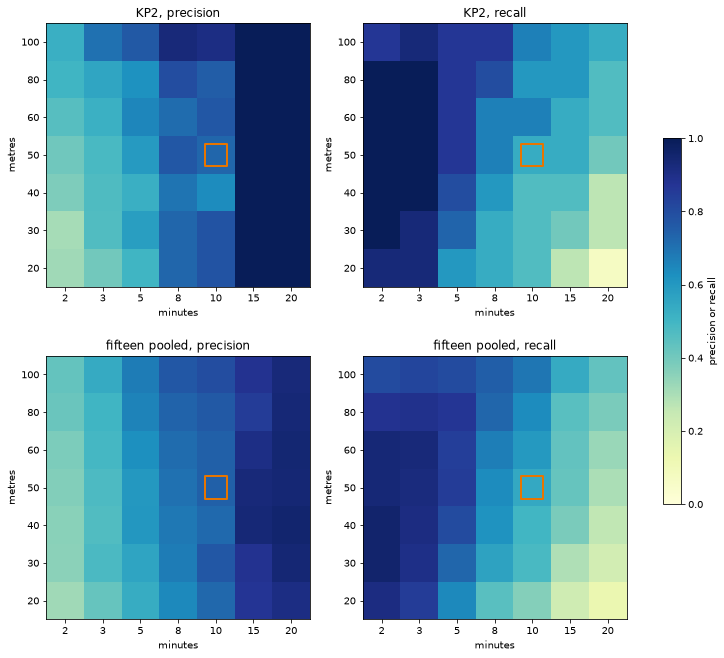

In [10]:
dists, mins = rules["surface"]["dist_m"], rules["surface"]["min"]
P, R, N = mob.threshold_surface(kp2, coded, dists, mins, min_overlap_s=rules["stay"]["overlap_s"])
pooled, i, j = json.load(open("data/stay_surface.json"))["pooled"], dists.index(50), mins.index(10)
print(f"pooled at 50 m and 10 min {pooled['precision'][i][j]:.2f}, {pooled['recall'][i][j]:.2f}   reference "
      f"{reference['traces']['pooled']['precision']:.2f}, {reference['traces']['pooled']['recall']:.2f}")
fig, axes = plt.subplots(2, 2, figsize=(13, 11), subplot_kw={"xlabel": "minutes", "ylabel": "metres"})
names = ["KP2, precision", "KP2, recall", "fifteen pooled, precision", "fifteen pooled, recall"]
for ax, Z, name in zip(axes.flat, (P, R, pooled["precision"], pooled["recall"]), names):
    im = ax.imshow(Z, cmap="YlGnBu", vmin=0, vmax=1, origin="lower")
    ax.scatter([j], [i], s=500, marker="s", facecolor="none", edgecolor="#e77500", lw=2)
    ax.set(xticks=range(len(mins)), xticklabels=mins, yticks=range(len(dists)), yticklabels=dists, title=name)
fig.colorbar(im, ax=axes, shrink=0.6).set_label("precision or recall")

Lower the thresholds and recall rises while precision falls, since short stops are found and every pause becomes a stay. Raise them and the rule keeps only the long, tight stops, nearly all real, and merges neighbouring rides. KP2 at 50 m and 10 minutes, the orange square, scores 0.73 and 0.53, and the fifteen pooled sit close, so the misses come from the stops' lengths and the queues' shapes, not one visitor's habits. No pair is right for every question, so your pair goes on the poster.

## KP2, read by a stranger

The cell reads KP2's day from the published files alone, the coded stops by type and the dataset's own summary row, as anyone who downloads them could.

In [11]:
every = pd.read_csv("data/themepark_coded_stops.csv.gz").query("participant_id == 'KP2'")
row = pd.read_csv("data/themepark_kbf_visits.csv.gz").set_index("participant_id").loc["KP2"]
longest, rs = coded.loc[coded["duration_min"].idxmax()], reference["traces"]["stranger"]
held = pd.IntervalIndex.from_arrays(coded["start"], coded["end"], closed="both").get_indexer(t) >= 0
step = np.hypot(np.diff(kp2["x"]), np.diff(kp2["y"]))
print(coded.groupby("type")["duration_min"].agg(["count", "mean", "min", "max"]).round(2).to_string())
print(f"arrived {mob.clock(t[0])}, left {mob.clock(t[-1])}, {(every['type'] == 'Attraction').sum()} "
      f"attractions, the longest stop {longest['poi_name']}, {longest['duration_min']:.1f} minutes from "
      f"{mob.clock(longest['start'])}   reference {rs['attractions']}, {rs['longest']['minutes']:.1f}")
print(f"{row['distance_traveled_m'] / 1000:.1f} km at {row['avg_speed_mps']:.2f} m/s in the dataset's row, "
      f"{step.sum() / 1000:.1f} km summed over every step, {step[held[1:] & held[:-1]].sum() / 1000:.1f} "
      f"km of it inside the coded stops   reference {rs['distance_km']:.1f}, {rs['fixes_km']:.1f}")

            count   mean   min    max
type                                 
Attraction      9  21.89  6.20  40.18
Bathroom        2   3.67  2.77   4.57
Commercial      2  29.90  2.95  56.85
Unlabeled       2   4.34  1.42   7.27
arrived 12:05, left 18:09, 10 attractions, the longest stop Saloon, 56.9 minutes from 14:49   reference 10, 56.9
4.3 km at 0.59 m/s in the dataset's row, 11.8 km summed over every step, 7.5 km of it inside the coded stops   reference 4.3, 11.8


Nothing in the files names the visitor, yet the day reads like a diary. Ten attractions, nine timed at about 22 minutes with the queue, two bathroom stops, a shop, and almost an hour at the Saloon, which reads as a meal. The dataset's row counts 4.3 km of walking between the stops, while the fixes sum to 11.8 km, most of it inside the stops, where queues shuffle, rides move and a resting receiver wanders. The lecture's fourth chapter asks who may read a trace like this.

## Your own trace, read and trimmed

The cell takes the first GPX or CSV file in `my_traces`, drops the unusable fixes, keeps the local clock, projects into metres and cuts 200 m at both ends.

In [12]:
path = mob.first_trace("my_traces")
if path is None:
    print(mob.NO_TRACE)
    raw, dropped, name = kp2, 0, "the specimen"
else:
    read, dropped = mob.clean_fixes(mob.read_trace(path))
    raw, name = mob.fixes_from_trace(read), path.name
own, head, tail = mob.trim_ends(raw, rules["trim_m"])
own_stays = mob.stays(own, rules["stay"]["dist_m"], rules["stay"]["min_s"])
print(f"{name} gave {len(raw):,} usable fixes and {dropped} dropped, {head} cut at the start and {tail} "
      f"at the end, {len(own):,} kept from {mob.clock(own['t_s'].min())} to {mob.clock(own['t_s'].max())}")
print(own_stays[["start", "end"]].map(mob.clock).to_string())

no trace of your own in my_traces yet, so the specimen stands in; drop a GPX or CSV file there and run again


the specimen gave 8,918 usable fixes and 0 dropped, 155 cut at the start and 158 at the end, 8,605 kept from 12:08 to 18:06
    start    end
0   12:44  12:55
1   12:57  13:24
2   13:37  14:05
3   14:17  14:29
4   14:29  14:47
5   15:28  15:46
6   15:54  16:17
7   16:20  16:32
8   16:32  16:51
9   16:55  17:15
10  17:18  17:44


Your trace goes through the hunt's rules before anything else runs. Only the points are read, never a name or a link from the file. Fixes without a time, at zero latitude and longitude, or far from the rest are dropped. The date goes and the clock stays in local time, so check that the span above matches your afternoon. The first and last 200 m are cut, since a trace starts and ends at a door. Then the same rule finds your stays, listed by their clock times.

## Your stays against your diary

The cell scores your stays against `my_traces/diary.csv` when it is there, the stops your team wrote down with their arrival and departure, and draws your stays on the walk network.

In [13]:
if path is None:
    print("no trace of yours yet, so there are no stays of yours to draw or to score against a diary")
elif Path("my_traces/diary.csv").exists():
    mine = mob.read_diary("my_traces/diary.csv")
    hit = mob.match_stays(own_stays, mine, min_overlap_s=rules["stay"]["overlap_s"])
    print(f"against the {len(mine)} stops of your diary precision {hit['precision']:.2f}, recall "
          f"{hit['recall']:.2f}, missed {', '.join(mine.loc[hit['unmatched_coded'], 'poi_name']) or 'none'}")
if path is not None:
    fig, ax = plt.subplots(figsize=(9, 9), subplot_kw={"xticks": [], "yticks": []})
    mob.show_traces(own, ax, colour="#1f3b73", lw=0.8, stays_df=own_stays)
    ax.autoscale(False)
    mob.show_graph(mob.load_graph("data/princeton_walk.graphml"), ax, colour="#bbbbbb", lw=0.5, zorder=0)

no trace of yours yet, so there are no stays of yours to draw or to score against a diary


The diary is your coded ground truth, a file `diary.csv` beside the trace with the columns stop, start and end, the clock times your team wrote at each station. Without it a stay is a stay, and nothing tells a station from a pause at a crossing. With it the specimen's two numbers become yours, and a precision far below one on a hunt is a story too, a team that waited where its diary says it walked. The map draws your trace and your stays over Princeton's walk network.

## Your trips on the walk graph

The cell snaps your stays to Princeton's walk network, measures the shortest path between consecutive stays, and counts the cells and hours your trace touches.

In [14]:
if path is None:
    print("no trace of yours yet, so there are no trips of yours to lay on Princeton's walk graph")
else:
    walk, p02 = mob.load_graph("data/princeton_walk.graphml"), gpd.read_file("data/layers.gpkg", layer="grid")
    own_trips, snap = mob.trips(own, own_stays), mob.nearest_nodes(walk, own_stays["x"], own_stays["y"])
    own_trips["network_m"] = [mob.route(walk, a, b)[1] for a, b in zip(snap[:-1], snap[1:])]
    own_trips["network_directness"] = own_trips["network_m"] / own_trips["walked_m"]
    print(own_trips[["walked_m", "network_m", "directness", "network_directness"]].round(2).to_string())
    touched = pd.DataFrame({"cell": mob.grid_cells(p02, own.x, own.y), "hour": own.t_s // 3600})
    touched = touched[touched["cell"] >= 0].drop_duplicates()
    print(f"{touched['cell'].nunique()} cells and {len(touched)} cell-hours; the class release counts "
          f"a cell and hour only with at least {rules['k']} trackers per 250 m cell of the P02 grid and hour")

no trace of yours yet, so there are no trips of yours to lay on Princeton's walk graph


On Princeton's walk network the directness of a trip is the shortest path between your two stays over the metres you walked, the study's measure. Near one, you took the paths the network knows. Far below one, a detour or a receiver that wandered between buildings; above one, a shortcut across a lawn the map lacks. The cell-hours are what your trace adds to the class's release, a tracker in a cell in an hour, published only where at least ten trackers share it.

## Your turn

The rule ran at ten minutes and missed six of the seven coded stops shorter than that. Lower the time threshold to five minutes on the specimen, score the rule again and read the timeline. Run the cell as it is, then change the marked value and run it again.

What did five minutes find that ten minutes missed, what did it invent, and which of precision and recall moved? Write your answer in one or two sentences. The answer comes in Friday's post, not in the kit.

10 minutes, 11 stays, 8 matched, precision 0.73, recall 0.53, 3 false alarms
missed Calico River Rapids 17.4 min, CRR Bathroom 2.8 min, CRR Bathroom 4.6 min, Wheeler Dealer 6.2 min, Lee's Last Stop Shop 3.0 min, Jaguar! 9.1 min, Sol Spin Line Stop 1.4 min


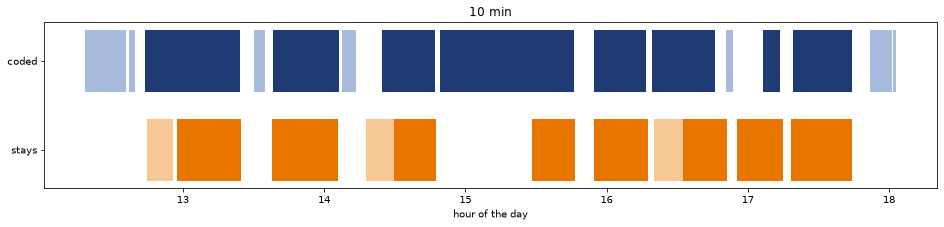

In [15]:
MIN_MINUTES = 10  # change me: 5
found = mob.stays(kp2, rules["stay"]["dist_m"], 60.0 * MIN_MINUTES)
r = mob.match_stays(found, coded, min_overlap_s=rules["stay"]["overlap_s"])
missed = coded.index.isin(r["unmatched_coded"])
print(f"{MIN_MINUTES} minutes, {len(found)} stays, {len(r['matched'])} matched, precision "
      f"{r['precision']:.2f}, recall {r['recall']:.2f}, {len(r['unmatched_detected'])} false alarms")
print("missed " + ", ".join(f"{n} {m:.1f} min" for n, m in
                            zip(coded["poi_name"][missed], coded["duration_min"][missed])))
fig, ax = plt.subplots(figsize=(16, 3))
ax.broken_barh(list(zip(coded["start"] / 3600, coded["duration_min"] / 60)), (0.65, 0.7),
               facecolors=np.where(missed, "#a9bbdc", "#1f3b73"))
ax.broken_barh(list(zip(found["start"] / 3600, found["duration_s"] / 3600)), (-0.35, 0.7),
               facecolors=np.where(found.index.isin(r["unmatched_detected"]), "#f6c896", "#e77500"))
ax.set(yticks=[0, 1], yticklabels=["stays", "coded"], xlabel="hour of the day", title=f"{MIN_MINUTES} min")
plt.show()

## Check your understanding

1. Every step of KP2's fixes sums to 11.8 km, the dataset's row to 4.3 km. Where does the rest come from, and what does it say about a threshold under 20 m?
2. Precision and recall are Lecture 04's error matrix on stays. What is a false alarm here, and why does a ten-minute rule miss most short stops but not all?
3. The leg from Wheeler Dealer to Silver Bullet has a directness of 0.48. Give two readings of it that are not an error.
4. Your trace lost its first and last 200 m and its date. What does each rule protect, and what can a stranger still read from your stays?

## Where we are

You turned twelve fixes and then one visitor's day into stays and trips with one rule and two thresholds, scored the rule against the diary that coded the day, measured how directly the visitor walked, traded the two thresholds, and read the day as a stranger would. Then you ran your own trace through the same chain. The thresholds are the analyst's, and they belong on the poster beside the score. In 07-04 the trips become a matrix between zones, your traces become counts per cell and hour, and the counts become a question of who can be found in them.

## Further resources

Nothing in this course requires anything below.

- Mining user similarity based on location history, Quannan Li and colleagues, ACM SIGSPATIAL GIS 2008, the stay rule, https://doi.org/10.1145/1463434.1463477
- Hidden Markov map matching through noise and sparseness, Paul Newson and John Krumm, ACM SIGSPATIAL GIS 2009, https://doi.org/10.1145/1653771.1653818
- Human mobility: models and applications, Hugo Barbosa and colleagues, Physics Reports 2018, sections 2 and 3, https://arxiv.org/abs/1710.00004
- Theme park visitor movement in Southern California, Dane Utley and Jürgen Hackl, Zenodo 2026, https://doi.org/10.5281/zenodo.20748587

The tables, numbers and this kit are the course's own work, published under CC BY 4.0. The street networks, the destinations and the isochrones derive from OpenStreetMap, licensed ODbL 1.0, copyright OpenStreetMap contributors: https://www.openstreetmap.org/copyright The theme-park fixes, coded stops and park layers are the dataset of Utley and Hackl 2026, CC BY 4.0, doi 10.5281/zenodo.20748587, recorded with the visitors' consent and published as codes.